# <span style="color:darkblue"> Lecture 16: Neural Networks and Tensor Flow </span>

<font size = "5">

In this class we will talk about how to set up <br>
a neural network classifier using Tensor Flow

For an introduction

https://www.youtube.com/watch?v=i8NETqtGHms

# <span style="color:darkblue"> I. Setup Working Environment </span>



<font size = "5">

We will be using a new library called "Tensor Flow" that is used <br>
to create neural network architectures

In Windows (Anaconda Prompt) or Mac (Terminal) type:

``` conda install tensorflow ```

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names


# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


<font size = "5">

Import tensor flow packages

In [7]:

%pip install tensorflow
# Reinstall a compatible TensorFlow build in the active notebook environment
%pip install --upgrade pip
%pip install --force-reinstall --no-cache-dir "tensorflow-cpu==2.15.0"
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\adamk\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ------------------------------------- -- 1.8/2.0 MB 20.2 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 10.8 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.1.1
    Uninstalling pip-26.1.1:
      Successfully uninstalled pip-26.1.1
Note: you may need to restart the kernel to use updated packages.


   ---------------------------------------- 0.0/300.9 MB ? eta -:--:--
    --------------------------------------- 4.7/300.9 MB 28.6 MB/s eta 0:00:11
   - -------------------------------------- 8.7/300.9 MB 23.4 MB/s eta 0:00:13
   - -------------------------------------- 10.2/300.9 MB 21.2 MB/s eta 0:00:14
   -- ------------------------------------- 16.0/300.9 MB 19.3 MB/s eta 0:00:15
   --- ------------------------------------ 24.4/300.9 MB 23.4 MB/s eta 0:00:12
   ---- ----------------------------------- 30.7/300.9 MB 26.7 MB/s eta 0:00:11
   ---- ----------------------------------- 33.0/300.9 MB 24.4 MB/s eta 0:00:11
   ----- ---------------------------------- 40.6/300.9 MB 24.6 MB/s eta 0:00:11
   ------ --------------------------------- 48.0/300.9 MB 25.9 MB/s eta 0:00:10
   ------- -------------------------------- 56.9/300.9 MB 27.7 MB/s eta 0:00:09
   -------- ------------------------------- 66.6/300.9 MB 29.5 MB/s eta 0:00:08
   ---------- ----------------------------- 75.5/30

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
chromadb 1.0.12 requires httpx>=0.27.0, but you have httpx 0.20.0 which is incompatible.
gradio 5.33.0 requires httpx>=0.24.1, but you have httpx 0.20.0 which is incompatible.
gradio-client 1.10.2 requires httpx>=0.24.1, but you have httpx 0.20.0 which is incompatible.
gradio-client 1.10.2 requires websockets<16.0,>=10.0, but you have websockets 17.2 which is incompatible.
huggingface-hub 1.8.0 requires httpx<1,>=0.23.0, but you have httpx 0.20.0 which is incompatible.
jupyterlab 4.3.6 requires httpx>=0.25.0, but you have httpx 0.20.0 which is incompatible.
langchain-core 0.3.64 requires packaging<25,>=23.2, but you have packaging 26.3 which is incompatible.
langsmith 

RecursionError: maximum recursion depth exceeded while calling a Python object

# <span style="color:darkblue"> II. Data </span>

<font size = "5">

Online Shoppers Purchasing Intention Dataset (OSHPID)

- This dataset contains information about user sessions
- It contains features data about user behavior 
while <br> navigating website
- The goal is to predict whether the customer will purchase or not

https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset


In [ ]:
# Fetch online data from the UC Irvine Machine Learning Repository API
online_shopping= fetch_ucirepo(id=468) 

# Extract
X = online_shopping.data.features
# Drop columns that contain non-numeric values
X = X.drop(columns = ["Month","VisitorType"])

# Extract label data
y = online_shopping.data.targets["Revenue"]


In [ ]:
# Convert to float types (avoids issues down the line)
X = np.asarray(X).astype(np.float32)
y = np.asarray(y).astype(np.float32)

<font size = "5">

Pre-process data prior to running model

In [ ]:
# Split into training and test
X_train, X_test, y_train, y_test = train_test_split(X,y , 
                                   random_state=104,  
                                   test_size=0.25,  
                                   shuffle=True) 

In [ ]:
# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.fit(X_test).transform(X_test)

# <span style="color:darkblue"> III. Training a neural network </span>


<font size = "5">

Define number of features in $X$

In [ ]:
k_features = X.shape[1]
print(k_features)

15


<font size = "5">

To define a neural network we start with a configuration setup

- We start with an empty canvas with "Keras"
- Then we successively add how many layers we want <br>
and what type

For more information about Keras layers:

https://www.educative.io/answers/what-are-keras-layers

In [ ]:
# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential()

2025-11-04 11:13:44.358408: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=16, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

NameError: name 'basic_model' is not defined

<font size = "5">

Define an optimizer

In [ ]:
# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

In [ ]:
# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

<font size = "5">

Estimate model

- The optimization algorithm proceeds sequentially, through epocs
- Set a random seed to ensure reproducibility

In [ ]:
# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

Epoch 1/100
289/289 [==============================] - 0s 440us/step - loss: 6.6818 - accuracy: 0.7841
Epoch 2/100
289/289 [==============================] - 0s 421us/step - loss: 0.8210 - accuracy: 0.8603
Epoch 3/100
289/289 [==============================] - 0s 410us/step - loss: 0.6388 - accuracy: 0.8642
Epoch 4/100
289/289 [==============================] - 0s 403us/step - loss: 0.6016 - accuracy: 0.8656
Epoch 5/100
289/289 [==============================] - 0s 408us/step - loss: 0.5993 - accuracy: 0.8630
Epoch 6/100
289/289 [==============================] - 0s 422us/step - loss: 0.5989 - accuracy: 0.8648
Epoch 7/100
289/289 [==============================] - 0s 423us/step - loss: 0.5551 - accuracy: 0.8626
Epoch 8/100
289/289 [==============================] - 0s 425us/step - loss: 0.5531 - accuracy: 0.8616
Epoch 9/100
289/289 [==============================] - 0s 553us/step - loss: 0.7121 - accuracy: 0.8565
Epoch 10/100
289/289 [==============================] - 0s 430us/step - l

# <span style="color:darkblue"> IV. Evaluate a neural network </span>


<font size = "5">

Obtain predicted probabilities and convert them to {0,1}

In [ ]:
# Convert to array
predicted_prob = basic_model.predict(X_test)
predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

97/97 [==============================] - 0s 339us/step


<font size = "5">

Obtain confusion matrix

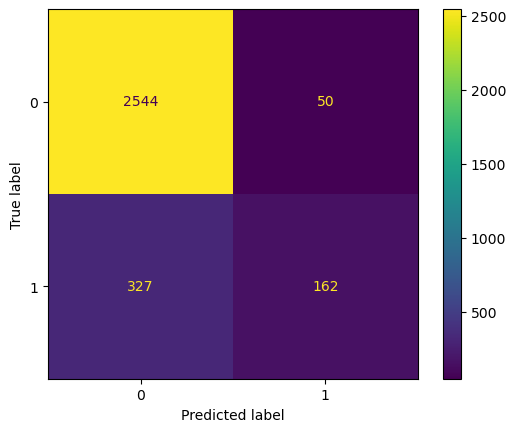

In [ ]:
# Obtain confusion matrix
cm = confusion_matrix(y_test, predicted)

displ = ConfusionMatrixDisplay(confusion_matrix=cm)
displ.plot()

<font size = "5">

At the moment we defined a very simple neural network <br>
with just an input layer and an output layer. <br>

Try it yourself!

- Increase the number of units in the input layer
- Does prediction accuracy improve?


In [ ]:
# Write your own code




<font size = "5">


Try it yourself!

- Add one or more hidden layers
- Does prediction accuracy improve?

In [ ]:
# Write your own code






<font size = "5">

Try it yourself!

- Import the Mashable dataset that we used earlier <br>
(you can find this in this in the ```ArticlesTrain.csv``` and <br>
```ArticlesTest.csv``` files in the ```data_raw``` folder)

- Try to set up a neural network with a simple input-output layer 

In [ ]:
# Write your own code






# <span style="color:darkblue"> V. Additional resources </span>

<font size = "5">

Quick guide:

https://www.tensorflow.org/tutorials/quickstart/beginner

Binary classification:

https://www.freecodecamp.org/news/binary-classification-made-simple-with-tensorflow/

Image classification:

https://www.tensorflow.org/tutorials/images/classification

